# DSC 550 11.3 Term Project: Final Project Submission

### Milestone 1

Many businesses rely on user reviews as a valuable source of feedback to identify opportunities for product improvement. For large platforms such as Tinder, the volume of reviews makes manual interpretation impractical. Automated text analysis offers a scalable way to identify patterns in user feedback and highlight potential product issues.

However, star ratings alone are not sufficient to identify actionable feedback. A low rating may reflect general dissatisfaction or frustration rather than a specific operational problem. At the same time, simple word-frequency analysis highlights common language but cannot distinguish between emotional sentiment and meaningful signals describing system failures or product limitations.

The goal of this project is therefore to develop a supervised text classification model that learns patterns associated with critical user dissatisfaction using review text. In this framework, 1–2 star reviews serve as proxy labels for high-risk feedback, while 4–5 star reviews represent general user experiences. By moving beyond simple word counts to a predictive modeling approach, the analysis aims to filter noise from large volumes of reviews and surface reviews that are more likely to describe actionable platform issues such as account bans, billing problems, or reliability failures.

In practical terms, such a system could support automated triage of user feedback. Instead of manually reading thousands of reviews, product teams could prioritize those most likely to contain operational issues and respond to them more quickly.

The dataset used for this analysis was obtained from Kaggle and contains more than 660,000 Google Play Store reviews for the Tinder mobile application (Ganesh, 2026). Each review includes the written content, star rating, timestamps, and additional metadata such as the number of users who marked the review as helpful.

Data source:
https://www.kaggle.com/datasets/shivkumarganesh/tinder-google-play-store-review

In [1]:
# Do a graphical analysis creating a minimum of four graphs. Label your graphs appropriately and explain/analyze the information provided by each graph.

# Step 0 - Load libraries/data
import numpy as np
import pandas as pd
import re
import string
import matplotlib.pyplot as plt
from IPython.display import display
from pandas.api.types import CategoricalDtype
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

data_file = "tinder_google_play_reviews.csv"
df = pd.read_csv(data_file)

print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head(5))

# Step 1 - Define targets
TEXT_COL = "content"
RATING_COL = "score"

work = df[[TEXT_COL, RATING_COL]].copy()
work = work.rename(columns={TEXT_COL: "review_text", RATING_COL: "rating"})

# Convert data types
work["review_text"] = work["review_text"].astype(str)
work["rating"] = pd.to_numeric(work["rating"], errors="coerce")

work = work.dropna(subset=["review_text", "rating"])
work = work[(work["rating"] >= 1) & (work["rating"] <= 5)]
work["rating"] = work["rating"].astype(int)

# Create ordered categorical target (ordinal)
rating_order = CategoricalDtype(categories=[1, 2, 3, 4, 5], ordered=True)
work["rating_ord"] = work["rating"].astype(rating_order)

print("Working shape:", work.shape)
print("Rating counts (ordinal):")
print(work["rating_ord"].value_counts().sort_index())
display(work.head(5))

# Step 2 - Clean text
def basic_clean(text: str) -> str:
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

work["review_clean"] = work["review_text"].apply(basic_clean)
work["review_len_words"] = work["review_clean"].str.split().apply(len)

display(work[["rating", "rating_ord", "review_len_words", "review_clean"]].head(5))

Shape: (666150, 11)
Columns: ['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion']


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,d0d05bfc-c59c-4486-9bd0-92015a71617f,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,don't get . your phone will get viruses,1,0,NaN,2026-01-29 23:41:00,NaN,NaN,NaN
1,bca15f59-5eef-4ee7-a239-929a85552275,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,It good,3,0,17.1.0,2026-01-29 23:08:55,NaN,NaN,17.1.0
2,97d12ba4-aa33-4373-8d6e-3b41c6e0b1fa,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,horrible!!! I subscribed and got banned for tr...,1,0,12.22.1,2026-01-29 23:08:24,NaN,NaN,12.22.1
3,b2125f48-ea0c-4b7c-8064-c1278f54bf7b,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,normal,1,0,17.1.0,2026-01-29 23:07:06,NaN,NaN,17.1.0
4,c83c01c6-4504-40a9-ada5-b139ecbe4dbb,A Google user,https://play-lh.googleusercontent.com/EGemoI2N...,This app is rogue.,1,0,15.3.0,2026-01-29 22:58:37,NaN,NaN,15.3.0


Working shape: (666150, 3)
Rating counts (ordinal):
rating_ord
1    279212
2     46593
3     49834
4     71704
5    218807
Name: count, dtype: int64


,review_text,rating,rating_ord
0,don't get . your phone will get viruses,1,1
1,It good,3,3
2,horrible!!! I subscribed and got banned for tr...,1,1
3,normal,1,1
4,This app is rogue.,1,1


,rating,rating_ord,review_len_words,review_clean
0,1,1,7,dont get your phone will get viruses
1,3,3,2,it good
2,1,1,36,horrible i subscribed and got banned for tryin...
3,1,1,1,normal
4,1,1,4,this app is rogue


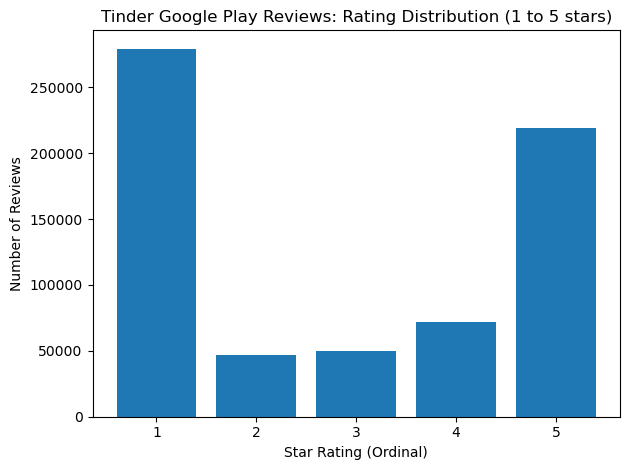

In [2]:
# Graph 1: Rating distribution (ordinal)
rating_counts = work["rating_ord"].value_counts().sort_index()

plt.figure()
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("Tinder Google Play Reviews: Rating Distribution (1 to 5 stars)")
plt.xlabel("Star Rating (Ordinal)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

This shows a strongly bimodal distribution with large concentrations of both one-star and five-star reviews. This pattern is common in review platforms, where users are most motivated to leave feedback when they have either very positive or very negative experiences. Because the modeling objective focuses on identifying meaningful complaints, this distribution supports grouping lower ratings together for further analysis.

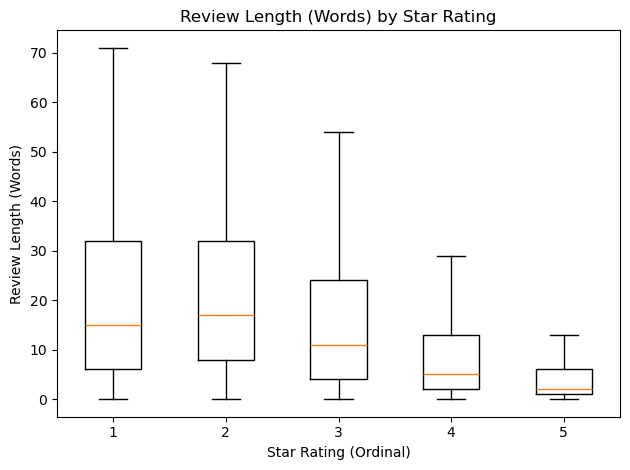

In [3]:
# Graph 2: Review length by rating (boxplot)
groups = []
labels = []
for r in [1, 2, 3, 4, 5]:
    groups.append(work.loc[work["rating"] == r, "review_len_words"].values)
    labels.append(str(r))

plt.figure()
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.title("Review Length (Words) by Star Rating")
plt.xlabel("Star Rating (Ordinal)")
plt.ylabel("Review Length (Words)")
plt.tight_layout()
plt.show()

This shows the distribution of review length across rating categories. Lower ratings tend to contain longer descriptions, suggesting that dissatisfied users are more likely to explain their experiences in detail. Interestingly, two-star reviews appear to have slightly higher average word counts than one-star reviews, while three-star reviews, although less frequent, often contain longer explanations that may include mixed feedback.

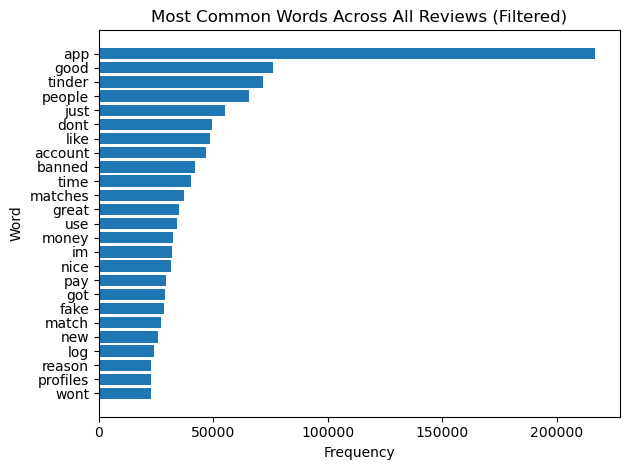

In [4]:
# Graph 3: Global common words
cv_all = CountVectorizer(
    stop_words=list(ENGLISH_STOP_WORDS),
    min_df=20,
    max_df=0.6
)

X_all = cv_all.fit_transform(work["review_clean"])
all_counts = X_all.sum(axis=0).A1
all_vocab = cv_all.get_feature_names_out()

top_idx = np.argsort(all_counts)[-25:][::-1]
top_words = all_vocab[top_idx]
top_vals = all_counts[top_idx]

plt.figure()
plt.barh(top_words[::-1], top_vals[::-1])
plt.title("Most Common Words Across All Reviews (Filtered)")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

domain_stopwords = {
    "tinder", "app", "apps",
    "account", "accounts",
    "dating", "date", "dates",
    "match", "matches",
    "people", "person",
    "im", "ive",
    "got", "use",
    "just", "dont", "like"
}

# Convert to list for sklearn
custom_stopwords = list(ENGLISH_STOP_WORDS.union(domain_stopwords))

Even after removing standard English stopwords, many high-frequency words were related to the application itself, such as “app” or “tinder,” and provided little predictive value. A global word frequency histogram was therefore used to identify additional domain-specific stopwords, which were added to a custom stopword list to reduce noise.

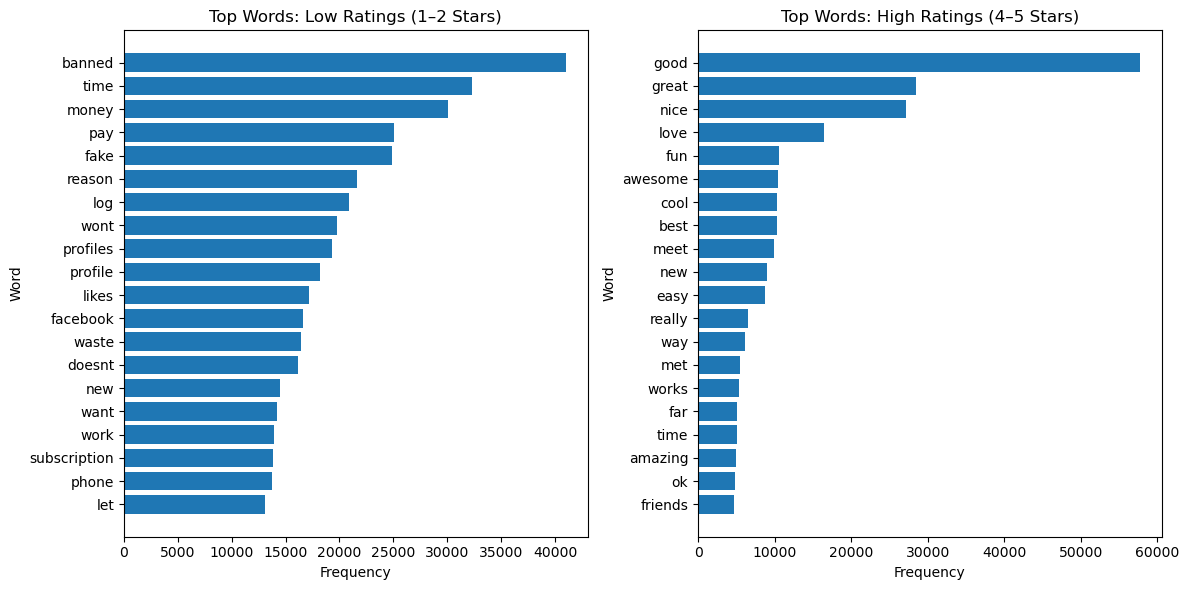

In [5]:
# Graph 4: Top words in low vs high ratings (side-by-side)
low = work[work["rating"].isin([1, 2])]["review_clean"]
high = work[work["rating"].isin([4, 5])]["review_clean"]

cv_low = CountVectorizer(stop_words=custom_stopwords, min_df=10, max_df=0.6)
low_X = cv_low.fit_transform(low)
low_counts = low_X.sum(axis=0).A1
low_vocab = np.array(cv_low.get_feature_names_out())
low_top_idx = np.argsort(low_counts)[-20:][::-1]
low_top_words = low_vocab[low_top_idx]
low_top_vals = low_counts[low_top_idx]

cv_high = CountVectorizer(stop_words=custom_stopwords, min_df=10, max_df=0.6)
high_X = cv_high.fit_transform(high)
high_counts = high_X.sum(axis=0).A1
high_vocab = np.array(cv_high.get_feature_names_out())
high_top_idx = np.argsort(high_counts)[-20:][::-1]
high_top_words = high_vocab[high_top_idx]
high_top_vals = high_counts[high_top_idx]

fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.barh(low_top_words[::-1], low_top_vals[::-1])
ax1.set_title("Top Words: Low Ratings (1–2 Stars)")
ax1.set_xlabel("Frequency")
ax1.set_ylabel("Word")

ax2 = fig.add_subplot(1, 2, 2)
ax2.barh(high_top_words[::-1], high_top_vals[::-1])
ax2.set_title("Top Words: High Ratings (4–5 Stars)")
ax2.set_xlabel("Frequency")
ax2.set_ylabel("Word")

plt.tight_layout()
plt.show()

After applying these filters and separating reviews by rating category, clearer patterns in language usage emerge. Negative reviews tend to include more specific terms related to platform functionality and perceived fairness, while positive reviews are dominated by short expressions of approval. These patterns suggest that negative reviews may contain more actionable information about operational issues, while positive reviews tend to reflect general satisfaction rather than specific product feedback.

Overall, the exploratory analysis reveals a highly polarized rating distribution, with reviews concentrated at the lowest and highest rating levels. Lower-rated reviews tend to be longer and contain more specific, actionable language related to account issues, billing, and perceived platform fairness, while higher-rated reviews are generally shorter and dominated by broad expressions of positive sentiment. A global term frequency analysis highlights the importance of removing domain-specific and generic words to reduce noise and avoid biased comparisons. These findings suggest that negative reviews may offer more diagnostic value for identifying improvement opportunities, while positive reviews reflect overall user satisfaction with limited specificity. Subsequent modeling will be necessary to assess which textual features are most predictive of ratings and to formalize these relationships in a way that supports data-driven product decisions.

### Milestone 2

With the exploratory analysis complete, the next step is constructing a modeling dataset aligned with the business objective.

The primary feature used for modeling is the cleaned review text, which captures the language used by users to describe their experiences. Additional numeric variables such as review length were retained as auxiliary features that may capture behavioral differences between types of reviews. The thumbs-up count was preserved for later comparison with model predictions rather than used directly as a predictive feature, since incorporating it during training could bias the model toward already visible or popular reviews. Timestamps were also retained to allow potential analysis of trends over time.

In [6]:
# import relevant variables from our cleaned dataset
model_df = work[["review_clean", "rating", "review_len_words"]].copy()

# add back in time and make sure it's formatted right
model_df["at"] = df.loc[work.index, "at"].values
model_df["at"] = pd.to_datetime(model_df["at"], errors="coerce")

# add back in thumbsUpCount
model_df["thumbsUpCount"] = df.loc[work.index, "thumbsUpCount"].values
model_df["thumbsUpCount"] = pd.to_numeric(model_df["thumbsUpCount"], errors="coerce").fillna(0)

# check structure/shape and inspect review length to determine whether max length should be trimmed
print(model_df.shape)
display(model_df.head())
print(model_df.isnull().sum())
print(model_df["review_len_words"].describe(percentiles=[.5, .9, .95, .999]))

(666150, 5)


,review_clean,rating,review_len_words,at,thumbsUpCount
0,dont get your phone will get viruses,1,7,2026-01-29 23:41:00,0
1,it good,3,2,2026-01-29 23:08:55,0
2,horrible i subscribed and got banned for tryin...,1,36,2026-01-29 23:08:24,0
3,normal,1,1,2026-01-29 23:07:06,0
4,this app is rogue,1,4,2026-01-29 22:58:37,0


review_clean        0
rating              0
review_len_words    0
at                  0
thumbsUpCount       0
dtype: int64
count    666150.000000
mean         15.590943
std          20.091858
min           0.000000
50%           8.000000
90%          41.000000
95%          60.000000
99.9%       115.000000
max         689.000000
Name: review_len_words, dtype: float64


To reduce ambiguity in the classification task, the dataset was restricted to 1–2 star reviews and 4–5 star reviews, while 3-star reviews were excluded. Mid-range reviews often represent mixed experiences and may introduce uncertainty into the training labels. Ratings were therefore converted into a binary target variable representing Critical versus General feedback.

Review length percentiles were also examined to identify extreme outliers. Reviews exceeding a conservative upper threshold were removed to reduce the influence of unusually long reviews that may represent spam or copied content, while preserving detailed complaint narratives.

In [7]:
# trim a conservative length well above (nearly double) the 99.9th percentile range
model_df = model_df[model_df["review_len_words"] <= 200].copy()

# restrict reviews to clear low/high classes for binary classification
model_df = model_df[model_df["rating"].isin([1, 2, 4, 5])].copy()

# define target variable: 1 = critical, 0 = general
model_df["critical"] = model_df["rating"].apply(lambda x: 1 if x in [1, 2] else 0)

print(model_df["critical"].value_counts())

critical
1    325734
0    290502
Name: count, dtype: int64


The dataset was then divided into training and testing subsets using an 80/20 split, with stratified sampling applied to maintain the original class proportions (approximately 53% critical and 47% general). Because the class imbalance is relatively small, no resampling techniques were required.

To avoid data leakage, text feature extraction was performed only on the training data. The vocabulary learned during training was then applied to transform the test data into the same feature space. Vocabulary size and matrix dimensions were inspected to verify that feature extraction was successful and to quantify the dimensionality of the modeling space.

In [8]:
# split data into train/test
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_text = model_df["review_clean"]
y = model_df["critical"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# use TF-IDF to weigh words based on importance rather than raw frequency alone
tfidf = TfidfVectorizer(
    stop_words=custom_stopwords,
    min_df=10,
    max_df=0.7,
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("TF-IDF train shape:", X_train.shape)
print("TF-IDF test shape:", X_test.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

TF-IDF train shape: (492988, 40063)
TF-IDF test shape: (123248, 40063)
Vocabulary size: 40063


At this stage, the dataset has been cleaned, structured, and transformed into a model-ready feature representation, providing the foundation for supervised classification in the final milestone.

### Milestone 3

To classify review text into critical and general feedback categories, a Logistic Regression model was selected.

Logistic Regression performs well on high-dimensional text datasets where the number of potential features (in this case, vocabulary terms) is large but each individual document contains only a small subset of those features. The TF-IDF feature representation used in this project results in a vocabulary of more than 40,000 unique terms, creating a high-dimensional but sparse feature space well suited for this modeling approach.

An additional advantage of Logistic Regression is interpretability. Each term receives a coefficient representing its relationship with the target class, allowing direct examination of which words contribute most strongly to predicting critical reviews.

Because the project objective is to prioritize detection of actionable complaints, evaluation focused on metrics that balance accurate detection with manageable false positives. In particular:

    Recall measures the proportion of true critical reviews that are successfully detected.
    Precision measures how often flagged reviews actually correspond to genuine complaints.
    ROC-AUC evaluates the model’s ability to separate the two classes across all possible thresholds.
    Precision-Recall AUC evaluates alert accuracy when prioritizing detection of the minority class.

Train class balance:
 critical
1    0.529
0    0.471
Name: proportion, dtype: float64
Test class balance:
 critical
1    0.529
0    0.471
Name: proportion, dtype: float64

Classification Report (Critical class = 1):
              precision    recall  f1-score   support

           0      0.902     0.898     0.900     58101
           1      0.909     0.913     0.911     65147

    accuracy                          0.906    123248
   macro avg      0.906     0.906     0.906    123248
weighted avg      0.906     0.906     0.906    123248



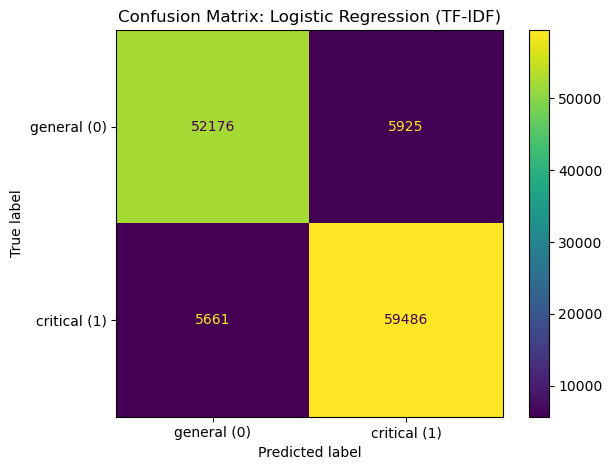

ROC-AUC: 0.960
Average Precision (PR-AUC): 0.961


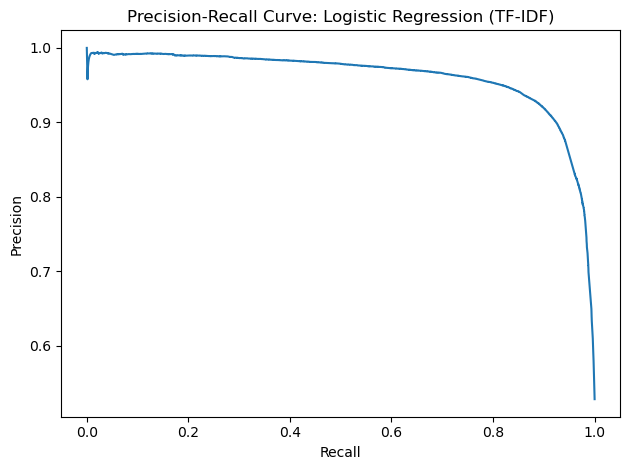


Top terms pushing toward CRITICAL (class 1):


,term,coef
0,banned,10.423649
1,useless,6.885201
2,garbage,6.829901
3,worst,6.797775
4,money,6.428118
5,trash,6.173258
6,scam,6.150042
7,terrible,5.945055
8,ban,5.721809
9,rubbish,5.593999



Top terms pushing toward GENERAL (class 0):


,term,coef
0,easy,-5.560643
1,does says,-5.377088
2,fun,-5.036500
3,great,-4.975315
4,awesome,-4.749289
5,wish,-4.656117
6,excellent,-4.538510
7,wonderful,-4.533864
8,dope,-4.408693
9,love,-4.269947



Example alert threshold for recall≈0.90: 0.558
Report at chosen alert threshold:
              precision    recall  f1-score   support

           0      0.890     0.911     0.901     58101
           1      0.919     0.900     0.910     65147

    accuracy                          0.905    123248
   macro avg      0.905     0.906     0.905    123248
weighted avg      0.906     0.905     0.905    123248



In [9]:
# import more libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# check balance of classes for train/test groups
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))

# use logistic regression for sparse, high-dimensional text classification with interpretable coefficients
logreg = LogisticRegression(
    max_iter=2000,
    solver="liblinear"
)

logreg.fit(X_train, y_train)

# evaluate model performance
y_pred = logreg.predict(X_test)
y_proba = logreg.predict_proba(X_test)[:, 1]

print("\nClassification Report (Critical class = 1):")
print(classification_report(y_test, y_pred, digits=3))

# show confusion matrix to visualize predictions versus true labels
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["general (0)", "critical (1)"])
disp.plot(values_format="d")
plt.title("Confusion Matrix: Logistic Regression (TF-IDF)")
plt.tight_layout()
plt.show()

# use ROC-AUC to evaluate overall class separability across thresholds
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC: {roc_auc:.3f}")

# use PR-AUC to evaluate alert quality when prioritizing critical reviews
ap = average_precision_score(y_test, y_proba)
print(f"Average Precision (PR-AUC): {ap:.3f}")

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

plt.figure()
plt.plot(recall, precision)
plt.title("Precision-Recall Curve: Logistic Regression (TF-IDF)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

# identify the most influential terms for each class
feature_names = tfidf.get_feature_names_out()
coefs = logreg.coef_.ravel()

top_pos_idx = np.argsort(coefs)[-20:][::-1]
top_neg_idx = np.argsort(coefs)[:20]

top_pos = pd.DataFrame({
    "term": feature_names[top_pos_idx],
    "coef": coefs[top_pos_idx]
})

top_neg = pd.DataFrame({
    "term": feature_names[top_neg_idx],
    "coef": coefs[top_neg_idx]
})

print("\nTop terms pushing toward CRITICAL (class 1):")
display(top_pos)

print("\nTop terms pushing toward GENERAL (class 0):")
display(top_neg)

# assign a target recall of 90% and determine the threshold required to achieve it
target_recall = 0.90
idx = np.where(recall >= target_recall)[0]

if len(idx) > 0:
    chosen_idx = idx[-1]
    if chosen_idx == len(thresholds):
        chosen_idx -= 1
    chosen_threshold = thresholds[chosen_idx]
    print(f"\nExample alert threshold for recall≈{target_recall:.2f}: {chosen_threshold:.3f}")
    y_alert = (y_proba >= chosen_threshold).astype(int)
    print("Report at chosen alert threshold:")
    print(classification_report(y_test, y_alert, digits=3))
else:
    print("\nCould not find threshold achieving target recall")

The model achieved strong performance with ROC-AUC ≈ 0.96 and PR-AUC ≈ 0.96, indicating excellent separation between critical and general feedback.

To emphasize detection of meaningful complaints, the classification threshold was adjusted from the default 0.50 to 0.558, which achieves approximately 90% recall for critical reviews while maintaining precision above 91%. This means the system can identify most potential issues while limiting the number of false alerts that would require manual review.

To better understand how the model prioritizes reviews, examples of highly ranked and lower-ranked critical reviews were examined. 

### Display Examples

In [10]:
# assign probability scores to each review in the test set
results_df = pd.DataFrame({
    "orig_index": X_test_text.index,
    "review_text": X_test_text.values,
    "true_label": y_test.values,
    "predicted_proba": y_proba
})

# add original review rating back in
results_df["rating"] = model_df.loc[results_df["orig_index"], "rating"].values

display(results_df.head())

# rank reviews by predicted critical probability
ranked_reviews = results_df.sort_values(
    by="predicted_proba",
    ascending=False
)

display(ranked_reviews.head(10))

# take the top critical reviews and display
top_critical = ranked_reviews[
    ranked_reviews["true_label"] == 1
].head(10)

display(top_critical[["rating", "predicted_proba"]])

# take the top critical 2-star reviews and display
top_2star = ranked_reviews[
    ranked_reviews["rating"] == 2
].head(5)

display(top_2star[["rating", "predicted_proba"]])

# break down individual reviews by term contribution
def explain_review(review_text_row):
    vec = tfidf.transform([review_text_row]).toarray().ravel()
    contributions = vec * coefs

    mask = contributions > 0
    if mask.sum() == 0:
        return pd.DataFrame(columns=["term", "contribution"])

    idx = np.argsort(contributions[mask])[-5:]
    terms = feature_names[mask][idx]
    vals = contributions[mask][idx]

    return pd.DataFrame({
        "term": terms[::-1],
        "contribution": vals[::-1]
    })

example_indices = top_critical.index[:5]

# display sample critical reviews and their contributions
for idx in example_indices:
    print("\n==============================")
    print("Rating:", results_df.loc[idx, "rating"])
    print("Predicted Critical Probability:", round(results_df.loc[idx, "predicted_proba"], 5))
    print("\nReview Excerpt:")
    print(results_df.loc[idx, "review_text"][:400])
    print("\nTop Contributing Terms:")
    display(explain_review(results_df.loc[idx, "review_text"]))

,orig_index,review_text,true_label,predicted_proba,rating
0,520942,its good,0,0.042589,5
1,191252,tinders gotta be kidding itself if it thinks i...,1,0.932500,1
2,32731,this app is genuinely a disservice to this gen...,1,0.999498,1
3,591796,great app meet some cool people would love for...,0,0.006066,5
4,360498,cool,0,0.010366,5


,orig_index,review_text,true_label,predicted_proba,rating
64427,57215,one of the worst apps out there mostly filled ...,1,0.999974,1
115879,57614,sorry i paid for this garbage been glitching a...,1,0.999958,1
6485,226790,pure fraud i paid 90 for premium and got banne...,1,0.999946,1
71812,109874,gold membership never been reported and sudden...,1,0.999943,1
78298,274433,i got banned for nothing,1,0.999938,2
46518,5173,my account was unlawfully banned,1,0.999938,1
109690,202594,my account is banned out of nowhere,1,0.999938,1
74532,170549,why is my acaunt banned,1,0.999938,1
43749,202174,my account has been banned,1,0.999938,1
80839,234323,got banned all my accounts,1,0.999938,1


,rating,predicted_proba
64427,1,0.999974
115879,1,0.999958
6485,1,0.999946
71812,1,0.999943
78298,2,0.999938
46518,1,0.999938
109690,1,0.999938
74532,1,0.999938
43749,1,0.999938
80839,1,0.999938


,rating,predicted_proba
78298,2,0.999938
73797,2,0.999938
106356,2,0.999938
34728,2,0.999938
71287,2,0.999713



Rating: 1
Predicted Critical Probability: 0.99997

Review Excerpt:
one of the worst apps out there mostly filled with scammers and bots when you report them tinder does absolutely nothing about it but when someone falsely reports your profile then your instantly banned with zero help from customer service and there appeals process is a joke banned when i havent had any matches or messages in over a month dont see how its possible dont waste your time with this pa

Top Contributing Terms:


,term,contribution
0,banned,1.530300
1,worst,0.631026
2,pathetic,0.623640
3,joke,0.539761
4,zero,0.538178


... (4 outputs left out)


Rating: 1
Predicted Critical Probability: 0.99994

Review Excerpt:
gold membership never been reported and suddenly tinder randomly banned my account for absolutely zero reason their customer service is non existent just a bot sending you the same message they probably use an algorithm that bans accounts and has a lot of false positives they take your money but randomly ban your account which im pretty sure is illegal in most countries

Top Contributing Terms:


,term,contribution
0,banned,0.866713
1,bans,0.723716
2,ban,0.696937
3,randomly,0.696652
4,zero,0.609613



Rating: 2
Predicted Critical Probability: 0.99994

Review Excerpt:
i got banned for nothing

Top Contributing Terms:


,term,contribution
0,banned,10.423649


In [11]:
# define low-confidence 1-star reviews
low_confidence_1star = ranked_reviews[
    (ranked_reviews["rating"] == 1) &
    (ranked_reviews["predicted_proba"] < 0.3)
].head(5)

display(low_confidence_1star)

example_indices = low_confidence_1star.index[:5]

# display sample low-confidence 1-star reviews and their contributions
for idx in example_indices:
    print("\n==============================")
    print("Rating:", results_df.loc[idx, "rating"])
    print("Predicted Critical Probability:", round(results_df.loc[idx, "predicted_proba"], 3))
    print("\nReview Excerpt:")
    print(results_df.loc[idx, "review_text"][:400])
    print("\nTop Contributing Terms:")
    display(explain_review(results_df.loc[idx, "review_text"]))

,orig_index,review_text,true_label,predicted_proba,rating
31310,172199,there is no feather to talk easily or call som...,1,0.299771,1
75613,354323,im probably ugly,1,0.299622,1
104790,114658,deceiving,1,0.299436,1
42395,301786,after 3 yrs i recived 0 hits now i know im tru...,1,0.299210,1
75363,209447,cant stay anoymous,1,0.299019,1



Rating: 1
Predicted Critical Probability: 0.3

Review Excerpt:
there is no feather to talk easily or call someone need that option

Top Contributing Terms:


,term,contribution
0,option,0.335749
1,talk,0.291753



Rating: 1
Predicted Critical Probability: 0.3

Review Excerpt:
im probably ugly

Top Contributing Terms:


,term,contribution
0,ugly,0.694762
1,probably,0.003071



Rating: 1
Predicted Critical Probability: 0.299

Review Excerpt:
deceiving

Top Contributing Terms:


,term,contribution



Rating: 1
Predicted Critical Probability: 0.299

Review Excerpt:
after 3 yrs i recived 0 hits now i know im truly ugly thanks tinder

Top Contributing Terms:


,term,contribution
0,ugly,0.479704
1,yrs,0.172326



Rating: 1
Predicted Critical Probability: 0.299

Review Excerpt:
cant stay anoymous

Top Contributing Terms:


,term,contribution


Reviews assigned high critical probabilities frequently contained words such as banned, fraud, waste, or load, often describing specific platform issues including account bans, payment problems, or application errors. In contrast, lower-confidence reviews were typically very short or described personal frustrations unrelated to platform functionality (for example, comments about not receiving matches).

This comparison demonstrates that the model is capable of distinguishing between actionable operational complaints and general dissatisfaction, supporting its potential use as a triage tool for prioritizing user feedback.

Overall, the modeling results demonstrate that review text contains strong predictive signals that can distinguish between general user sentiment and operational complaints. The Logistic Regression classifier trained on TF-IDF features achieved strong performance across multiple evaluation metrics, indicating that the language used in reviews reliably reflects whether users are describing actionable issues. By adjusting the decision threshold to prioritize recall, the model can surface the majority of critical complaints while maintaining a high level of precision, making it practical for use as a review triage system. Examination of individual review examples further confirms that highly ranked reviews tend to contain detailed descriptions of functional problems, while lower-confidence reviews are often short or express general frustration. Together, these results suggest that automated text classification can effectively prioritize meaningful user feedback and help organizations respond more quickly to emerging platform issues.